# Clase 5 — Evaluar sin mapa: Monte Carlo y TD

**RL a ciegas** · curso de aprendizaje por refuerzo (*reinforcement learning*, RL) · vía profunda

Basado en Sutton & Barto, cap. 5 (5.1, predicción Monte Carlo) y cap. 6 (6.1–6.3: predicción TD, sus ventajas y el entrenamiento por lotes), en Stanford CS234 (Brunskill), clase 3, y en Schultz, Dayan y Montague (1997) para la dopamina.

**La pregunta de hoy:** si nadie te da el mapa, ¿cuánto vale estar en una casilla? ¿Hay que esperar a terminar la partida para saberlo?

En las clases 3 y 4 calculamos valores con `env.P` y `env.R`: el mapa entero. Hoy el agente **no los tiene**: solo juega y mira qué pasa. Nosotros sí tenemos el mapa, y lo usamos para una sola cosa: calcular la respuesta correcta y ver qué tan cerca queda el agente. Vamos a ver:

1. **Partidas sin mapa**: qué ve el agente y qué política vamos a evaluar.
2. **Monte Carlo de primera visita**: promediar los retornos de lo que pasó.
3. **Promedio incremental**: corregir de a una partida, con $\alpha = 1/n$ o con $\alpha$ fijo.
4. **TD(0)**: corregir en cada paso, apoyándose en el valor de la casilla siguiente.
5. **El error $\delta$** a lo largo de una partida (y la dopamina).
6. **Sesgo y varianza**: Monte Carlo contra TD con varios $\alpha$.
7. **Equivalencia de certeza**: armar el mapa con lo jugado y resolver Bellman.

Y un ejercicio: cambiar $\alpha$ y la cantidad de partidas.

> Cómo usar este notebook: ejecutar las celdas en orden (Colab: *Entorno de ejecución → Ejecutar todas*). Tarda menos de un minuto.

## Preparación

La primera celda escribe el archivo `cave_env.py` con **la cueva** de todo el curso. Así el notebook funciona solo, también en Colab. No hace falta leerla.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Importamos la cueva y las bibliotecas de siempre, y fijamos una semilla. Las convenciones son las de las clases 3 y 4: **+1 al entrar a la salida**, la salida es absorbente y vale 0 (ahí ya no queda nada por cobrar), el primer paso no se descuenta y $\gamma = 0{,}99$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cave_env import CaveEnv, ACTION_NAMES

SEMILLA = 0
np.random.seed(SEMILLA)
GAMMA = 0.99

La celda siguiente define las **herramientas** (la política a evaluar, jugar partidas, Monte Carlo, TD, la equivalencia de certeza y los dibujos). Está plegada: no hace falta leerla, solo ejecutarla.

Una aclaración importante: las funciones que **aprenden** (`mc_primera_visita`, `td0`, `contar` y `certeza`) solo reciben partidas, es decir, listas de experiencias $(s, a, r, s')$. Nunca miran `env.P` ni `env.R`. El mapa lo usan solo `valor_verdadero` (la respuesta correcta, para comparar) y `politica_flechas` (la política que nos dan para evaluar).

In [3]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
import matplotlib.patheffects as pe

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5,
    "lines.linewidth": 2, "axes.axisbelow": True,
})
COL_MC, COL_TD, COL_CE = COLORES[1], COLORES[0], COLORES[2]


# ---------- la política que nos dan (y su valor verdadero: esto SÍ usa el mapa) ----------
def politica_flechas(env, gamma=0.99):
    """Las flechas óptimas de la clase 4 (iteración de valor con el mapa)."""
    V = np.zeros(env.nS)
    for _ in range(10_000):
        V_nuevo = (env.R + gamma * env.P @ V).max(axis=1)
        if np.max(np.abs(V_nuevo - V)) < 1e-12:
            break
        V = V_nuevo
    return (env.R + gamma * env.P @ V_nuevo).argmax(axis=1)


def tabla_politica(env, flechas, eps):
    """pi[s, a]: con prob. eps tira el dado (cualquiera de las 4); si no, sigue la flecha."""
    pi = np.full((env.nS, env.nA), eps / env.nA)
    pi[np.arange(env.nS), flechas] += 1 - eps
    return pi


def valor_verdadero(env, pi, gamma):
    """V^pi con el mapa: V = (I − γ P^pi)^(-1) R^pi (clases 3 y 4). Devuelve V, P^pi y R^pi."""
    Ppi = np.einsum("sa,sat->st", pi, env.P); Rpi = (pi * env.R).sum(axis=1)
    return np.linalg.solve(np.eye(env.nS) - gamma * Ppi, Rpi), Ppi, Rpi


# ---------- jugar: lo único que tiene el agente ----------
def jugar(env, flechas, eps, rng, inicio=None):
    """Una partida hasta la salida. Devuelve la lista de experiencias (s, a, r, s').
    Usa solo env.reset y env.step, como un jugador en la cueva a oscuras."""
    env.reset()
    if inicio is not None:
        env.s = inicio
    s, partida = env.s, []
    while True:
        a = int(rng.integers(env.nA)) if rng.random() < eps else int(flechas[s])
        s2, r, fin, info = env.step(a)
        partida.append((s, a, r, s2))
        s = s2
        if info["reached_goal"]:
            return partida
        if fin:
            raise RuntimeError("la partida se cortó antes de llegar: subí max_steps")


def inicio_al_azar(env, rng):
    """Una casilla al azar que no sea la salida."""
    s = int(rng.integers(env.nS - 1))
    return s if s < env.goal else s + 1


def camino_de(partida):
    return [partida[0][0]] + [x[3] for x in partida]


def retornos_desde_primera_visita(partida, gamma):
    """{s: G desde la PRIMERA visita a s}. Se recorre la partida de atrás para adelante: G = r + γ G."""
    G, primera = 0.0, {}
    for s, a, r, s2 in reversed(partida):
        G = r + gamma * G
        primera[s] = G                  # al ir hacia atrás, el último que queda es el de la primera visita
    return primera


# ---------- aprender sin mapa ----------
def mc_primera_visita(V, N, partida, gamma, alfa=None):
    """Monte Carlo de primera visita. alfa=None: promedio exacto (α = 1/n); si no, α fijo."""
    for s, G in retornos_desde_primera_visita(partida, gamma).items():
        N[s] += 1
        paso = 1.0 / N[s] if alfa is None else alfa
        V[s] += paso * (G - V[s])


def td0(V, partida, gamma, alfa):
    """TD(0): después de CADA paso, V(s) += α [r + γ V(s') − V(s)]. Devuelve los δ de la partida.
    La salida nunca se actualiza: su V queda en 0 (ahí ya no queda nada por cobrar)."""
    deltas = []
    for s, a, r, s2 in partida:
        delta = r + gamma * V[s2] - V[s]
        V[s] += alfa * delta
        deltas.append(delta)
    return np.array(deltas)


def contar(cuentas, premios, partida):
    """Equivalencia de certeza: cuántas veces se pasó de s a s' y cuánto premio se cobró saliendo de s."""
    for s, a, r, s2 in partida:
        cuentas[s, s2] += 1; premios[s] += r


def certeza(cuentas, premios, gamma):
    """P̂[s, s'] = cuentas / veces que salió de s;  R̂[s] = premio promedio;  V̂ = (I − γ P̂)^(-1) R̂.
    Casillas nunca visitadas: fila de ceros (V̂ = 0)."""
    n = cuentas.sum(axis=1)
    P_hat = np.divide(cuentas, n[:, None], out=np.zeros_like(cuentas), where=n[:, None] > 0)
    R_hat = np.divide(premios, n, out=np.zeros_like(premios), where=n > 0)
    V_hat = np.linalg.solve(np.eye(len(n)) - gamma * P_hat, R_hat)
    return P_hat, R_hat, V_hat


def error_rms(V, V_true, env):
    """Raíz del promedio de los errores al cuadrado, en las 59 casillas que no son la salida."""
    ng = np.arange(env.nS) != env.goal
    return float(np.sqrt(np.mean((V[ng] - V_true[ng]) ** 2)))


def comparar(env, flechas, eps, V_true, gamma, alfas, n_partidas, semillas, marcas=(), casilla=None):
    """MC (α = 1/n), MC con α fijo y TD(0) con α fijo ven EXACTAMENTE las mismas partidas (inicio al azar).
    Devuelve el error RMS después de cada partida (semillas x partidas) de cada método, el valor estimado
    de 'casilla' partida a partida, y el error de la equivalencia de certeza en las partidas de 'marcas'."""
    nombres = ["MC 1/n"] + [f"MC α={a:g}" for a in alfas] + [f"TD α={a:g}" for a in alfas]
    ng = np.arange(env.nS) != env.goal
    err = {k: np.zeros((len(semillas), n_partidas)) for k in nombres}
    traza = {k: np.zeros((len(semillas), n_partidas)) for k in nombres}
    err_ce = np.zeros((len(semillas), len(marcas)))
    for i, sem in enumerate(semillas):
        rng = np.random.default_rng(sem)
        V = {k: np.zeros(env.nS) for k in nombres}
        N = {k: np.zeros(env.nS) for k in nombres}
        cuentas, premios = np.zeros((env.nS, env.nS)), np.zeros(env.nS)
        for k in range(n_partidas):
            partida = jugar(env, flechas, eps, rng, inicio=inicio_al_azar(env, rng))
            mc_primera_visita(V["MC 1/n"], N["MC 1/n"], partida, gamma)
            for a in alfas:
                mc_primera_visita(V[f"MC α={a:g}"], N[f"MC α={a:g}"], partida, gamma, alfa=a)
                td0(V[f"TD α={a:g}"], partida, gamma, a)
            for nom in nombres:
                err[nom][i, k] = np.sqrt(np.mean((V[nom][ng] - V_true[ng]) ** 2))
                if casilla is not None:
                    traza[nom][i, k] = V[nom][casilla]
            if marcas:
                contar(cuentas, premios, partida)
                if (k + 1) in marcas:
                    err_ce[i, list(marcas).index(k + 1)] = error_rms(certeza(cuentas, premios, gamma)[2], V_true, env)
    return {"err": err, "traza": traza, "err_ce": err_ce, "nombres": nombres}


def largos_azar(env, n, semilla=0, max_pasos=30_000):
    """Pasos hasta la salida de n partidas de la política al azar desde S (simulación rápida, en paralelo;
    -1 si no llegó en max_pasos)."""
    rng = np.random.default_rng(semilla)
    nxt = np.array([[env._move(s, a)[0] for a in range(env.nA)] for s in range(env.nS)])
    s = np.full(n, env.start); T = np.full(n, -1)
    for t in range(1, max_pasos + 1):
        idx = np.flatnonzero(T < 0)
        if idx.size == 0:
            break
        s[idx] = nxt[s[idx], rng.integers(env.nA, size=idx.size)]
        T[idx[s[idx] == env.goal]] = t
    return T


# ---------- dibujos de la cueva ----------
def plot_cave(env, values=None, policy=None, path=None, ax=None, title=None, cmap="magma", clim=None,
              mark=None, numbers=False, fmt="{:.2f}"):
    """env.plot + escala de color elegible (calculada sin la salida), flechas con borde, círculos y números opcionales."""
    ax = env.plot(values=values, policy=policy, path=path, ax=ax, title=title, cmap=cmap)
    if values is not None:
        if clim is None:
            v = np.asarray(values, dtype=float)[np.arange(env.nS) != env.goal]
            v = v[np.isfinite(v)]
            clim = (v.min(), v.max()) if v.size else (0, 1)
            if clim[1] - clim[0] < 1e-12:
                clim = (clim[1] - 1, clim[1])
        ax.images[-1].set_clim(*clim)
    for t in ax.texts:
        t.set_path_effects([pe.withStroke(linewidth=2.5, foreground="black")])
    if mark is not None:
        for m in np.atleast_1d(mark):
            r, c = env.free[int(m)]
            ax.plot(c, r, "o", mfc="none", mec="#00e5ff", mew=2.5, ms=15)
    if numbers and values is not None:
        for s, (r, c) in enumerate(env.free):
            if np.isfinite(values[s]) and s != env.goal:
                ax.text(c, r + 0.3, fmt.format(values[s]), ha="center", va="center", fontsize=7, color="w",
                        path_effects=[pe.withStroke(linewidth=2, foreground="black")])
    return ax


def plot_agent_view(env, partida, ax, title):
    """Lo que 've' el agente: solo las paredes que tocó (gris claro) y su recorrido."""
    tocadas = set()
    for s, a, r, s2 in partida:
        if s2 == s:
            (fr, fc), (dr, dc) = env.free[s], [(-1, 0), (0, 1), (1, 0), (0, -1)][a]
            tocadas.add((fr + dr, fc + dc))
    env.plot(ax=ax, show_walls=False, path=camino_de(partida), title=title)
    for (r, c) in tocadas:
        ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color=(0.8, 0.8, 0.8)))
    return tocadas


def banda(ax, x, err, color, label, ls="-"):
    """Promedio sobre semillas y banda de ± 1 desvío."""
    m, sd = err.mean(0), err.std(0)
    ax.plot(x, m, color=color, label=label, ls=ls)
    ax.fill_between(x, np.maximum(m - sd, 1e-4), m + sd, color=color, alpha=0.15, lw=0)

## 1. Partidas sin mapa

Sin mapa, el agente no tiene $P$ ni $R$. Lo único que tiene es lo que le pasa: en cada paso, dónde estaba, qué hizo, qué premio cobró y adónde fue a parar. Una **partida** (*episode*) es una lista de esas experiencias:

$$(s_0, a_0, r_0, s_1),\ (s_1, a_1, r_1, s_2),\ \dots$$

Hoy el agente no elige nada nuevo: **evalúa una política que le dieron**. La pregunta es solo cuánto vale cada casilla si se juega con esa política.

### Paso 1 — ¿Qué política evaluamos?

La candidata natural es el dado de la clase 3, cuyo valor ya conocemos: $V(S) = 0{,}0136$. Pero el dado tarda muchísimo en salir, y casi todas sus partidas valen casi 0. Comparémoslo con otra política: **las flechas óptimas de la clase 4, con ruido**. En cada paso, con probabilidad $\varepsilon = 0{,}7$ tira el dado (cualquiera de las cuatro direcciones, incluida la buena) y si no, sigue la flecha. Para las dos calculamos el valor verdadero con el mapa (esto lo hacemos nosotros, no el agente) y medimos cuánto duran sus partidas desde S.

In [4]:
env = CaveEnv(max_steps=100_000)          # sin corte práctico: todas las partidas terminan en la salida
EPS = 0.7
flechas = politica_flechas(env, GAMMA)
pi = tabla_politica(env, flechas, EPS)
V_true, P_true, R_true = valor_verdadero(env, pi, GAMMA)
V_azar = valor_verdadero(env, tabla_politica(env, flechas, 1.0), GAMMA)[0]      # ε = 1: siempre el dado

T_azar = largos_azar(env, 5000, semilla=1)
G_azar = np.where(T_azar > 0, GAMMA ** (T_azar - 1.0), 0.0)
rng = np.random.default_rng(1)
T_eps = np.array([len(jugar(env, flechas, EPS, rng, inicio=env.start)) for _ in range(5000)])
G_eps = GAMMA ** (T_eps - 1.0)

print(f"{'política':24s} {'V(S) verdadero':>15s} {'pasos (mediana)':>16s} {'pasos (máx.)':>13s} {'desvío de G / V(S)':>19s}")
for nombre, V_, T_, G_ in [("el dado (clase 3)", V_azar, T_azar, G_azar),
                           (f"flechas con ε = {EPS}", V_true, T_eps, G_eps)]:
    print(f"{nombre:24s} {V_[env.start]:>15.4f} {np.median(T_):>16.0f} {T_.max():>13d} {G_.std() / V_[env.start]:>19.2f}")
print(f"\n5000 partidas desde S con cada una.  Con el dado, partidas de más de 1000 pasos: {100 * np.mean((T_azar > 1000) | (T_azar < 0)):.0f} %")

política                  V(S) verdadero  pasos (mediana)  pasos (máx.)  desvío de G / V(S)
el dado (clase 3)                 0.0136             1036          8877                3.11
flechas con ε = 0.7               0.5004               69           208                0.22

5000 partidas desde S con cada una.  Con el dado, partidas de más de 1000 pasos: 52 %


Con el dado, una partida típica dura más de mil pasos y el desvío de los retornos es varias veces más grande que el valor que queremos estimar: para ver algo habría que jugar millones de pasos. Con las flechas ruidosas, las partidas duran decenas de pasos y aun así cada partida es distinta (el 70 % de las veces el agente tira el dado), así que hay ruido de verdad para comparar los métodos. **Desde acá evaluamos las flechas con $\varepsilon = 0{,}7$.** Su valor verdadero, calculado con el mapa, es la respuesta correcta contra la que vamos a medir todo.

### Paso 2 — Lo que ve el agente

Una partida desde S, dibujada dos veces: lo que ve el agente (solo las paredes que tocó, como en el juego) y lo que sabemos nosotros (el mapa entero).

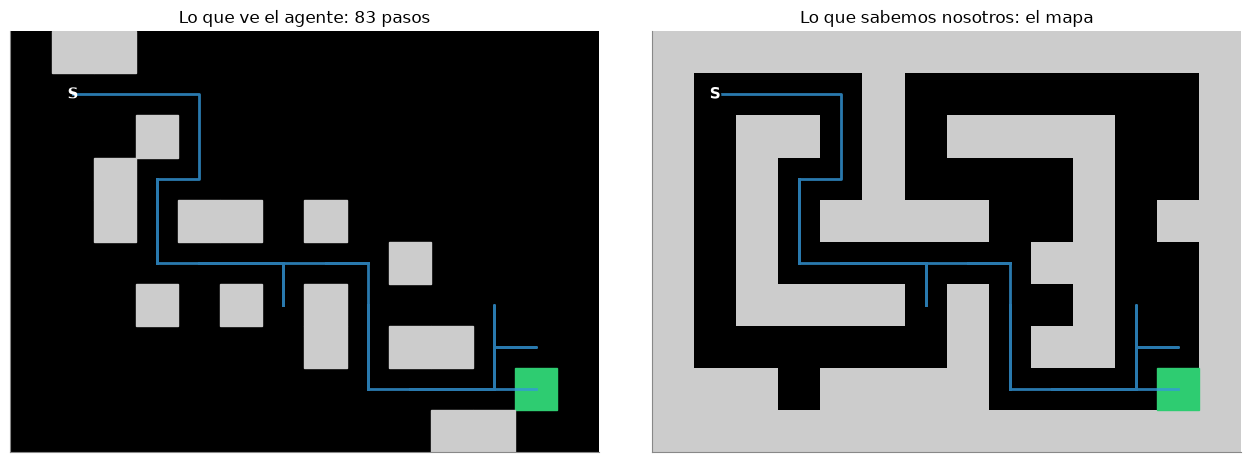

pasos: 83   paredes tocadas: 17   premio total: 1
primeras 5 experiencias (s, a, r, s'):
   (1, 1)  ↑  r = 0  ->  (1, 1)   (chocó)
   (1, 1)  →  r = 0  ->  (1, 2)
   (1, 2)  ↑  r = 0  ->  (1, 2)   (chocó)
   (1, 2)  →  r = 0  ->  (1, 3)
   (1, 3)  →  r = 0  ->  (1, 4)
última: (8, 11)  →  r = 1  ->  (8, 12) (la salida)


In [5]:
rng = np.random.default_rng(3)
partida = jugar(env, flechas, EPS, rng, inicio=env.start)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
tocadas = plot_agent_view(env, partida, axs[0], f"Lo que ve el agente: {len(partida)} pasos")
plot_cave(env, path=camino_de(partida), ax=axs[1], title="Lo que sabemos nosotros: el mapa")
plt.tight_layout(); plt.show()

print(f"pasos: {len(partida)}   paredes tocadas: {len(tocadas)}   premio total: {sum(x[2] for x in partida):g}")
print("primeras 5 experiencias (s, a, r, s'):")
for s, a, r, s2 in partida[:5]:
    print(f"   {env.free[s]}  {ACTION_NAMES[a]}  r = {r:g}  ->  {env.free[s2]}" + ("   (chocó)" if s2 == s else ""))
s, a, r, s2 = partida[-1]
print(f"última: {env.free[s]}  {ACTION_NAMES[a]}  r = {r:g}  ->  {env.free[s2]} (la salida)")

Todo lo de hoy sale de listas como esa. La idea de fondo: **reemplazar la suma sobre $P$ de la ecuación de Bellman por promedios de lo que efectivamente pasó**.

### Paso 3 — El valor verdadero (solo para comparar)

Este es el mapa de $V^\pi$ que el agente tendría que descubrir, calculado con $P$ y $R$ como en la clase 3. Marcamos tres casillas que vamos a seguir: **S**, el **cruce** (5, 6) de la clase 4, y la casilla (8, 10), a dos pasos de la salida.

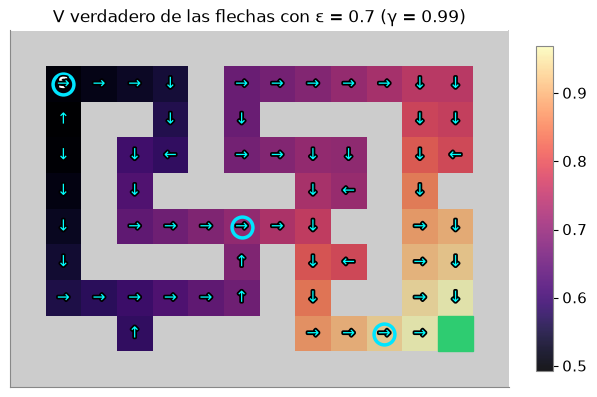

V verdadero S              = 0.5004
V verdadero cruce (5, 6)   = 0.7099
V verdadero cerca (8, 10)  = 0.9379
mínimo: 0.4918 en (2, 1)   máximo (sin la salida): 0.9691   V(salida) = 0


In [6]:
cruce = env.pos2s[(5, 6)]
cerca = env.pos2s[(8, 10)]
SEGUIDAS = {"S": env.start, "cruce (5, 6)": cruce, "cerca (8, 10)": cerca}
ng = np.arange(env.nS) != env.goal
CLIM = (V_true[ng].min(), V_true[ng].max())

plot_cave(env, values=V_true, policy=flechas, mark=list(SEGUIDAS.values()), clim=CLIM,
          title=f"V verdadero de las flechas con ε = {EPS} (γ = {GAMMA})")
plt.show()
for nombre, s in SEGUIDAS.items():
    print(f"V verdadero {nombre:14s} = {V_true[s]:.4f}")
print(f"mínimo: {V_true[ng].min():.4f} en {env.free[int(np.argmin(np.where(ng, V_true, np.inf)))]}   "
      f"máximo (sin la salida): {V_true[ng].max():.4f}   V(salida) = {V_true[env.goal]:.0f}")

## 2. Monte Carlo de primera visita

El valor es el retorno **esperado** desde una casilla (clase 3): $V(s) = \mathbb{E}[G_t \mid s_t = s]$. Sin mapa no se puede calcular el promedio sobre todas las partidas posibles, pero sí el promedio sobre las partidas **jugadas**. Ese es el método de **Monte Carlo** (*Monte Carlo*, MC):

1. Jugar una partida hasta el final.
2. Para cada casilla visitada, calcular el retorno $G$ desde la **primera vez** que se la pisó en esa partida (*first-visit*).
3. Promediar, para cada casilla, los retornos de todas las partidas.

$$V(s) \approx \frac{G^{(1)}(s) + G^{(2)}(s) + \dots + G^{(n)}(s)}{n}$$

### Paso 1 — Los retornos de una partida

Con la partida del paso anterior: el retorno desde la primera visita a cada casilla. Como el único premio es el +1 del final, $G = \gamma^{k-1}$ si desde esa visita faltaban $k$ pasos.

La partida visitó 24 casillas distintas en 83 pasos.
   G desde la primera visita a S              = 0.4386   (V verdadero = 0.5004)
   G desde la primera visita a cruce (5, 6)   = 0.5870   (V verdadero = 0.7099)
   G desde la primera visita a cerca (8, 10)  = 0.8262   (V verdadero = 0.9379)


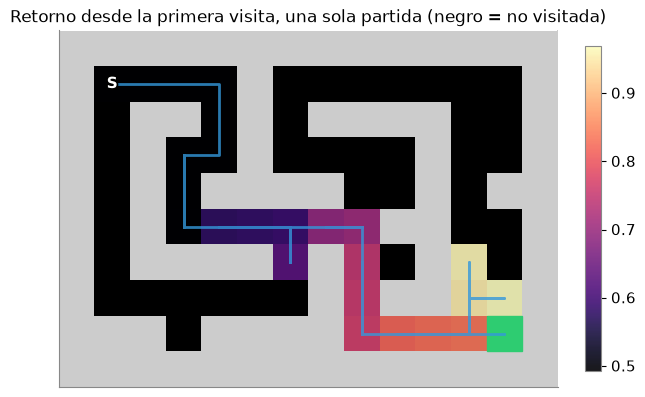

In [7]:
G_partida = retornos_desde_primera_visita(partida, GAMMA)
print(f"La partida visitó {len(G_partida)} casillas distintas en {len(partida)} pasos.")
for nombre, s in SEGUIDAS.items():
    if s in G_partida:
        print(f"   G desde la primera visita a {nombre:14s} = {G_partida[s]:.4f}   (V verdadero = {V_true[s]:.4f})")
    else:
        print(f"   {nombre}: no la visitó")
vals = np.full(env.nS, np.nan)
for s, G in G_partida.items():
    vals[s] = G
plot_cave(env, values=vals, path=camino_de(partida), clim=CLIM,
          title="Retorno desde la primera visita, una sola partida (negro = no visitada)")
plt.show()

Una sola partida ya da un número para cada casilla que visitó, pero es **una muestra**: si la partida tuvo suerte, el número es alto; si dio vueltas, es bajo. Hay que promediar muchas.

### Paso 2 — Muchas partidas

Si todas las partidas empezaran en S, las casillas lejos del camino casi nunca recibirían visitas. Por eso, desde acá, **cada partida empieza en una casilla al azar** (*exploring starts*). Jugamos 300 partidas y seguimos el promedio de las tres casillas marcadas, partida a partida.

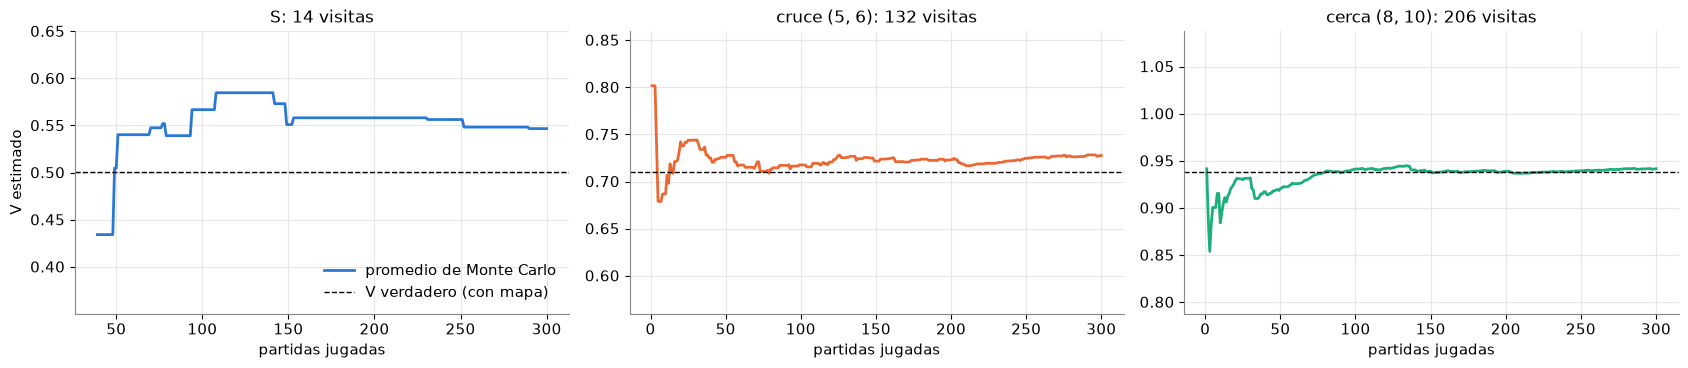

S              MC después de 300 partidas = 0.5467   verdadero = 0.5004   visitas = 14
cruce (5, 6)   MC después de 300 partidas = 0.7276   verdadero = 0.7099   visitas = 132
cerca (8, 10)  MC después de 300 partidas = 0.9416   verdadero = 0.9379   visitas = 206
casillas nunca visitadas: 0   error RMS en las 59 casillas = 0.0169


In [8]:
N_MC = 300
rng = np.random.default_rng(10)
V_mc, N_vis = np.zeros(env.nS), np.zeros(env.nS)
historia_mc = np.full((N_MC, env.nS), np.nan)
retornos_cruce = []                                   # los guardamos para la sección 3
partidas_mc = []                                      # y las partidas, para la sección 7
for k in range(N_MC):
    p = jugar(env, flechas, EPS, rng, inicio=inicio_al_azar(env, rng))
    partidas_mc.append(p)
    G_p = retornos_desde_primera_visita(p, GAMMA)
    if cruce in G_p:
        retornos_cruce.append(G_p[cruce])
    mc_primera_visita(V_mc, N_vis, p, GAMMA)
    historia_mc[k] = np.where(N_vis > 0, V_mc, np.nan)

fig, axs = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, (nombre, s), col in zip(axs, SEGUIDAS.items(), [COLORES[0], COLORES[1], COLORES[2]]):
    ax.plot(np.arange(1, N_MC + 1), historia_mc[:, s], color=col, label="promedio de Monte Carlo")
    ax.axhline(V_true[s], color="k", ls="--", lw=1, label="V verdadero (con mapa)")
    ax.set_title(f"{nombre}: {int(N_vis[s])} visitas"); ax.set_xlabel("partidas jugadas")
    ax.set_ylim(V_true[s] - 0.15, V_true[s] + 0.15)
axs[0].set_ylabel("V estimado"); axs[0].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

for nombre, s in SEGUIDAS.items():
    print(f"{nombre:14s} MC después de {N_MC} partidas = {V_mc[s]:.4f}   verdadero = {V_true[s]:.4f}   "
          f"visitas = {int(N_vis[s])}")
print(f"casillas nunca visitadas: {int(np.sum(N_vis[ng] == 0))}   error RMS en las 59 casillas = {error_rms(V_mc, V_true, env):.4f}")

Al principio el promedio salta (pocas muestras); con más partidas se acerca a la línea punteada, que el agente nunca vio. Cada casilla aprende **a su ritmo**: la que se visita más, se estabiliza antes. Ahora el mapa entero, al lado del verdadero (misma escala de color):

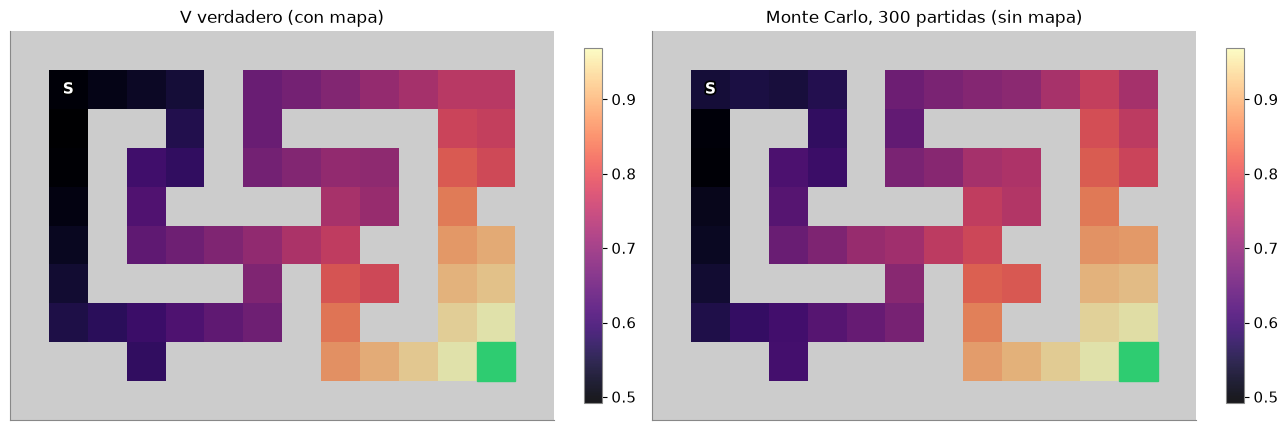

error máximo: 0.0462 en la casilla (1, 1) (14 visitas)


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
plot_cave(env, values=V_true, ax=axs[0], clim=CLIM, title="V verdadero (con mapa)")
plot_cave(env, values=V_mc, ax=axs[1], clim=CLIM, title=f"Monte Carlo, {N_MC} partidas (sin mapa)")
plt.tight_layout(); plt.show()
peor = int(np.argmax(np.abs(V_mc - V_true)))
print(f"error máximo: {abs(V_mc[peor] - V_true[peor]):.4f} en la casilla {env.free[peor]} ({int(N_vis[peor])} visitas)")

## 3. Promediar sin guardar todo: el promedio incremental

Para promediar no hace falta guardar todos los retornos. Si $V_{n-1}$ es el promedio de los primeros $n-1$ y llega un retorno nuevo $G$:

$$V_{n} = V_{n-1} + \frac{1}{n}\,\big(G - V_{n-1}\big)$$

Se lee así: **corregir el promedio viejo una fracción de la sorpresa** $G - V$. Con $\alpha = 1/n$ es exactamente el promedio. Con un $\alpha$ **fijo** (por ejemplo 0,1) el promedio pesa más lo reciente y olvida lo viejo: sirve si el mundo cambia, pero nunca deja de temblar.

$$V \leftarrow V + \alpha\,\big(G - V\big)$$

### Paso 1 — Los retornos del cruce, uno por uno

Tomamos los retornos desde el cruce que juntamos en la sección 2 y los promediamos de tres maneras.

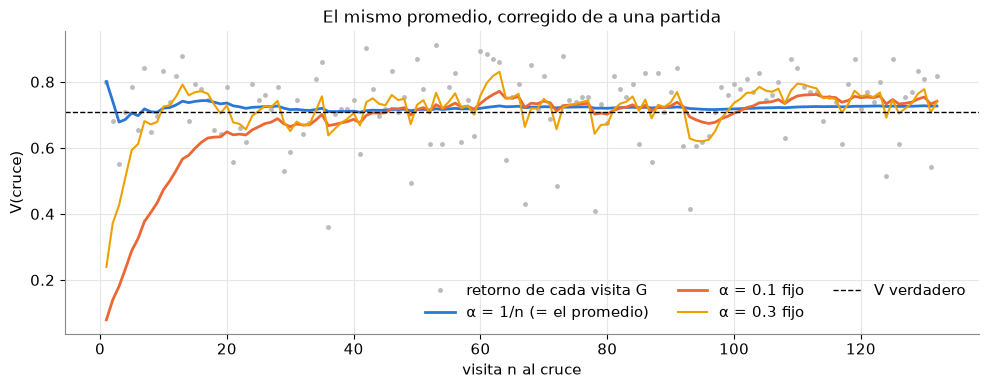

retornos desde el cruce: 132   (mínimo 0.362, máximo 0.914)
promedio común = 0.727555   incremental α = 1/n = 0.727555   diferencia máxima en todo el recorrido = 7.8e-16
último valor:  α = 0.1 → 0.7419   α = 0.3 → 0.7405   verdadero: 0.7099
temblor en las últimas 50 visitas (desvío):  α = 1/n 0.0032   α = 0.1 0.0233   α = 0.3 0.0444


In [10]:
G_c = np.array(retornos_cruce)
n = np.arange(1, len(G_c) + 1)
promedio_comun = np.cumsum(G_c) / n                 # guardando todo

def incremental(G, alfa=None):
    V, salida = 0.0, []
    for i, g in enumerate(G, start=1):
        V += (1 / i if alfa is None else alfa) * (g - V)
        salida.append(V)
    return np.array(salida)

inc_1n = incremental(G_c)
inc_01 = incremental(G_c, alfa=0.1)
inc_03 = incremental(G_c, alfa=0.3)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(n, G_c, ".", color="#bbbbbb", ms=5, label="retorno de cada visita G")
ax.plot(n, inc_1n, color=COLORES[0], label="α = 1/n (= el promedio)")
ax.plot(n, inc_01, color=COLORES[1], label="α = 0.1 fijo")
ax.plot(n, inc_03, color=COLORES[3], lw=1.5, label="α = 0.3 fijo")
ax.axhline(V_true[cruce], color="k", ls="--", lw=1, label="V verdadero")
ax.set_xlabel("visita n al cruce"); ax.set_ylabel("V(cruce)")
ax.set_title("El mismo promedio, corregido de a una partida"); ax.legend(frameon=False, ncol=3, loc="lower right")
plt.tight_layout(); plt.show()

print(f"retornos desde el cruce: {len(G_c)}   (mínimo {G_c.min():.3f}, máximo {G_c.max():.3f})")
print(f"promedio común = {promedio_comun[-1]:.6f}   incremental α = 1/n = {inc_1n[-1]:.6f}   "
      f"diferencia máxima en todo el recorrido = {np.max(np.abs(promedio_comun - inc_1n)):.1e}")
print(f"último valor:  α = 0.1 → {inc_01[-1]:.4f}   α = 0.3 → {inc_03[-1]:.4f}   verdadero: {V_true[cruce]:.4f}")
print(f"temblor en las últimas 50 visitas (desvío):  α = 1/n {inc_1n[-50:].std():.4f}   "
      f"α = 0.1 {inc_01[-50:].std():.4f}   α = 0.3 {inc_03[-50:].std():.4f}")

El promedio común y el incremental con $\alpha = 1/n$ son **la misma cuenta** (la diferencia es error de redondeo). Con $\alpha$ fijo, el estimado sigue a los últimos retornos y tiembla; cuanto más grande $\alpha$, más tiembla. Con $\alpha$ fijo, el retorno de hace $k$ visitas pesa $\alpha(1-\alpha)^k$: lo viejo se va olvidando.

Esta forma, **valor viejo + $\alpha$ · (objetivo − valor viejo)**, es el molde de todo lo que sigue. Monte Carlo usa como objetivo el retorno $G$ de la partida entera. TD va a cambiar solo el objetivo.

## 4. TD(0): corregir en cada paso

Monte Carlo tiene que **esperar al final** de la partida para conocer $G$. La **diferencia temporal** (*temporal difference*, TD) no espera: después de cada paso usa lo que acaba de pasar ($r$) más lo que **ya cree** que vale la casilla adonde llegó, $V(s')$. Es la ecuación de Bellman de la clase 3 con **una sola muestra** de $s'$ en lugar del promedio sobre $P$:

$$V(s) \leftarrow V(s) + \alpha\,\big[\,r + \gamma V(s') - V(s)\,\big]$$

El objetivo $r + \gamma V(s')$ se apoya en otra estimación (*bootstrapping*). La salida vale 0, así que en el último paso el objetivo es solo $r = 1$.

### Paso 1 — Una actualización a mano

Arrancamos TD con $V = 0$ en todas las casillas, lo dejamos jugar 200 partidas con $\alpha = 0{,}1$ y después miramos **un solo paso** de una partida nueva que empieza en el cruce, con todos los números.

In [11]:
ALFA = 0.1
rng = np.random.default_rng(20)
V_td = np.zeros(env.nS)
for _ in range(200):
    td0(V_td, jugar(env, flechas, EPS, rng, inicio=inicio_al_azar(env, rng)), GAMMA, ALFA)

nueva = jugar(env, flechas, EPS, np.random.default_rng(21), inicio=cruce)
s, a, r, s2 = nueva[0]
objetivo = r + GAMMA * V_td[s2]
delta = objetivo - V_td[s]
V_nuevo = V_td[s] + ALFA * delta
print(f"Paso: {env.free[s]} --{ACTION_NAMES[a]}--> {env.free[s2]},  premio r = {r:g}")
print(f"   V(s)  = {V_td[s]:.4f}     V(s') = {V_td[s2]:.4f}     α = {ALFA}     γ = {GAMMA}")
print(f"   objetivo TD = r + γ V(s') = {r:g} + {GAMMA} · {V_td[s2]:.4f} = {objetivo:.4f}")
print(f"   δ = objetivo − V(s) = {objetivo:.4f} − {V_td[s]:.4f} = {delta:+.4f}")
print(f"   V(s) nuevo = V(s) + α δ = {V_td[s]:.4f} + {ALFA} · {delta:+.4f} = {V_nuevo:.4f}")
print(f"   (verdaderos: V(s) = {V_true[s]:.4f},  V(s') = {V_true[s2]:.4f})")

Paso: (5, 6) --→--> (5, 7),  premio r = 0
   V(s)  = 0.4507     V(s') = 0.5671     α = 0.1     γ = 0.99
   objetivo TD = r + γ V(s') = 0 + 0.99 · 0.5671 = 0.5614
   δ = objetivo − V(s) = 0.5614 − 0.4507 = +0.1107
   V(s) nuevo = V(s) + α δ = 0.4507 + 0.1 · +0.1107 = 0.4618
   (verdaderos: V(s) = 0.7099,  V(s') = 0.7418)


TD no necesitó saber cómo terminaba la partida: le alcanzó un paso. Y como $V(s')$ todavía está por debajo del verdadero (arrancó en 0), el objetivo también queda corto: TD hereda los errores de sus propias estimaciones. Eso es el **sesgo** de TD, que vamos a medir en la sección 6.

### Paso 2 — La primera partida: qué corrige cada método

Con todo en $V = 0$, jugamos **una** partida desde S y miramos qué casillas cambian con cada método (los dos con $\alpha = 0{,}1$).

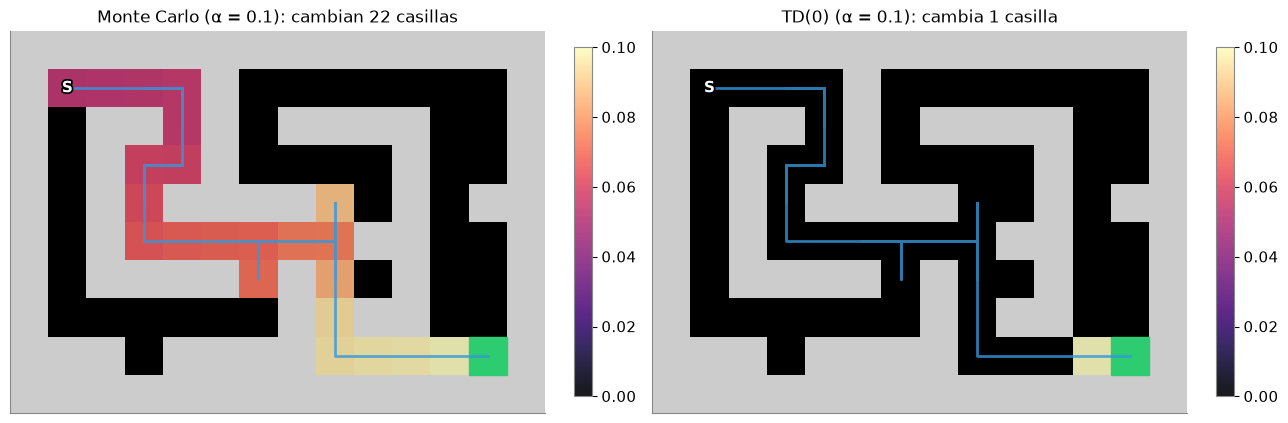

partida de 65 pasos, 22 casillas distintas
Monte Carlo cambió 22 casillas;  TD cambió 1: (8, 11), la última antes de la salida (V = 0.10)


In [12]:
primera = jugar(env, flechas, EPS, np.random.default_rng(5), inicio=env.start)
V_mc1, N_mc1, V_td1 = np.zeros(env.nS), np.zeros(env.nS), np.zeros(env.nS)
mc_primera_visita(V_mc1, N_mc1, primera, GAMMA, alfa=ALFA)
td0(V_td1, primera, GAMMA, ALFA)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, Vx, nombre in [(axs[0], V_mc1, "Monte Carlo (α = 0.1)"), (axs[1], V_td1, "TD(0) (α = 0.1)")]:
    plot_cave(env, values=np.where(Vx > 0, Vx, np.nan), path=camino_de(primera), ax=ax, clim=(0, 0.1),
              title=f"{nombre}: cambia{'n' if np.sum(Vx > 0) != 1 else ''} {int(np.sum(Vx > 0))} casilla{'s' if np.sum(Vx > 0) != 1 else ''}")
plt.tight_layout(); plt.show()
print(f"partida de {len(primera)} pasos, {len(set(camino_de(primera)[:-1]))} casillas distintas")
print(f"Monte Carlo cambió {int(np.sum(V_mc1 > 0))} casillas;  TD cambió {int(np.sum(V_td1 > 0))}: "
      f"{env.free[int(np.argmax(V_td1))]}, la última antes de la salida (V = {V_td1.max():.2f})")

Monte Carlo corrige **todas** las casillas de la partida, con el retorno real. TD, en la primera partida, solo corrige **la última**: en todos los demás pasos $r = 0$ y $V(s') = 0$, así que no hay nada que corregir. El +1 se va a ir propagando hacia atrás, una casilla por vez, partida tras partida (como el frente de valor de la clase 3).

### Paso 3 — El valor que se corrige paso a paso

Ahora una partida más adelante: el TD del paso 1, que ya jugó 200 partidas. Recorremos una partida desde S paso a paso. A la izquierda, el valor de cada casilla que pisa, antes de corregirlo, contra el verdadero; en el medio, la corrección $\alpha\,\delta$ de cada paso; a la derecha, cuánto cambió cada casilla al terminar la partida.

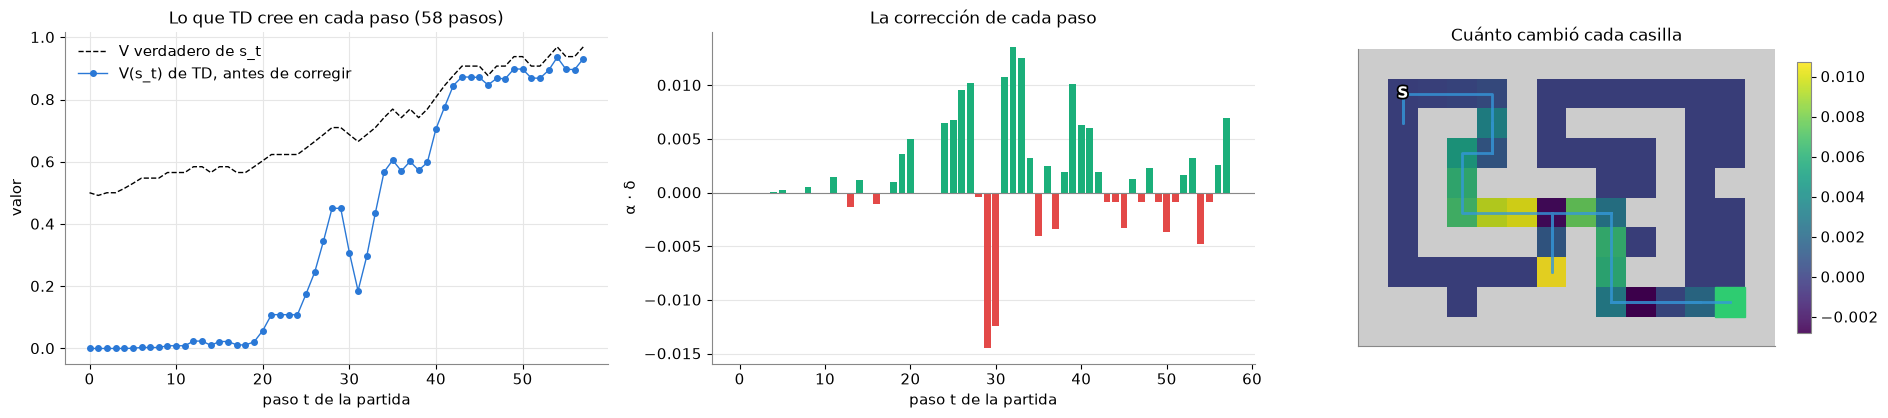

pasos: 58   correcciones hacia arriba: 30   hacia abajo: 28   nulas: 0
corrección más grande: +0.0136 en el paso 32, casilla (6, 6) (V antes = 0.296, verdadero = 0.687)
V(S): antes de la partida = 1.7e-06   después = 9.5e-06   verdadero = 0.5004


In [13]:
V_antes = V_td.copy()
p4 = jugar(env, flechas, EPS, np.random.default_rng(22), inicio=env.start)
V_paso = V_td.copy()
antes, correccion = [], []
for s, a, r, s2 in p4:
    antes.append(V_paso[s])
    d = r + GAMMA * V_paso[s2] - V_paso[s]
    V_paso[s] += ALFA * d
    correccion.append(ALFA * d)
antes, correccion = np.array(antes), np.array(correccion)
t = np.arange(len(p4))
estados = [x[0] for x in p4]

fig, axs = plt.subplots(1, 3, figsize=(19, 4.3), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
axs[0].plot(t, [V_true[s] for s in estados], "--", color="k", lw=1, label="V verdadero de s_t")
axs[0].plot(t, antes, "o-", color=COL_TD, ms=4, lw=1, label="V(s_t) de TD, antes de corregir")
axs[0].set_xlabel("paso t de la partida"); axs[0].set_ylabel("valor"); axs[0].legend(frameon=False, loc="upper left")
axs[0].set_title(f"Lo que TD cree en cada paso ({len(p4)} pasos)")
axs[1].bar(t, correccion, color=np.where(correccion >= 0, COLORES[2], COLORES[7]), width=0.8)
axs[1].axhline(0, color="#888888", lw=0.8); axs[1].grid(axis="x", visible=False)
axs[1].set_xlabel("paso t de la partida"); axs[1].set_ylabel("α · δ"); axs[1].set_title("La corrección de cada paso")
plot_cave(env, values=V_paso - V_antes, path=camino_de(p4), ax=axs[2], cmap="viridis",
          title="Cuánto cambió cada casilla")
plt.tight_layout(); plt.show()
print(f"pasos: {len(p4)}   correcciones hacia arriba: {int(np.sum(correccion > 1e-12))}   "
      f"hacia abajo: {int(np.sum(correccion < -1e-12))}   nulas: {int(np.sum(np.abs(correccion) <= 1e-12))}")
k = int(np.argmax(correccion))
print(f"corrección más grande: {correccion[k]:+.4f} en el paso {k}, casilla {env.free[estados[k]]} "
      f"(V antes = {antes[k]:.3f}, verdadero = {V_true[estados[k]]:.3f})")
print(f"V(S): antes de la partida = {V_antes[env.start]:.1e}   después = {V_paso[env.start]:.1e}   verdadero = {V_true[env.start]:.4f}")

Cada paso corrige un poquito una sola casilla, apenas pasa, sin esperar a saber cómo termina la partida. Las correcciones más grandes están en el **frente**: casillas que todavía valen poco pero cuya vecina ya recibió valor. Cerca de la salida ya casi no queda nada que corregir; lejos, al principio de la partida, todavía no llegó nada (S sigue valiendo casi 0 después de 200 partidas). Con $\alpha = 0{,}1$, cada corrección es chica: hacen falta muchas pasadas.

## 5. El error $\delta$ a lo largo de una partida

La cantidad que TD usa para corregir tiene nombre: el **error de diferencia temporal** (*TD error*),

$$\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t)$$

Es **la sorpresa**: lo que pasó (el premio más lo que ahora espero) menos lo que esperaba antes. Si $\delta > 0$, el paso salió mejor de lo esperado; si $\delta < 0$, peor; si $\delta = 0$, nada que aprender.

### Paso 1 — $\delta$ en tres momentos

Miramos los $\delta$ de una misma partida desde S en tres momentos:

1. **Sin saber nada** ($V = 0$).
2. **Después de aprender**: TD con $\alpha = 0{,}1$ después de 3000 partidas.
3. **Premio que no llega**: el mismo agente que aprendió y la misma partida, pero esta vez la salida **no paga**.

En los tres casos solo calculamos $\delta$, sin corregir nada.

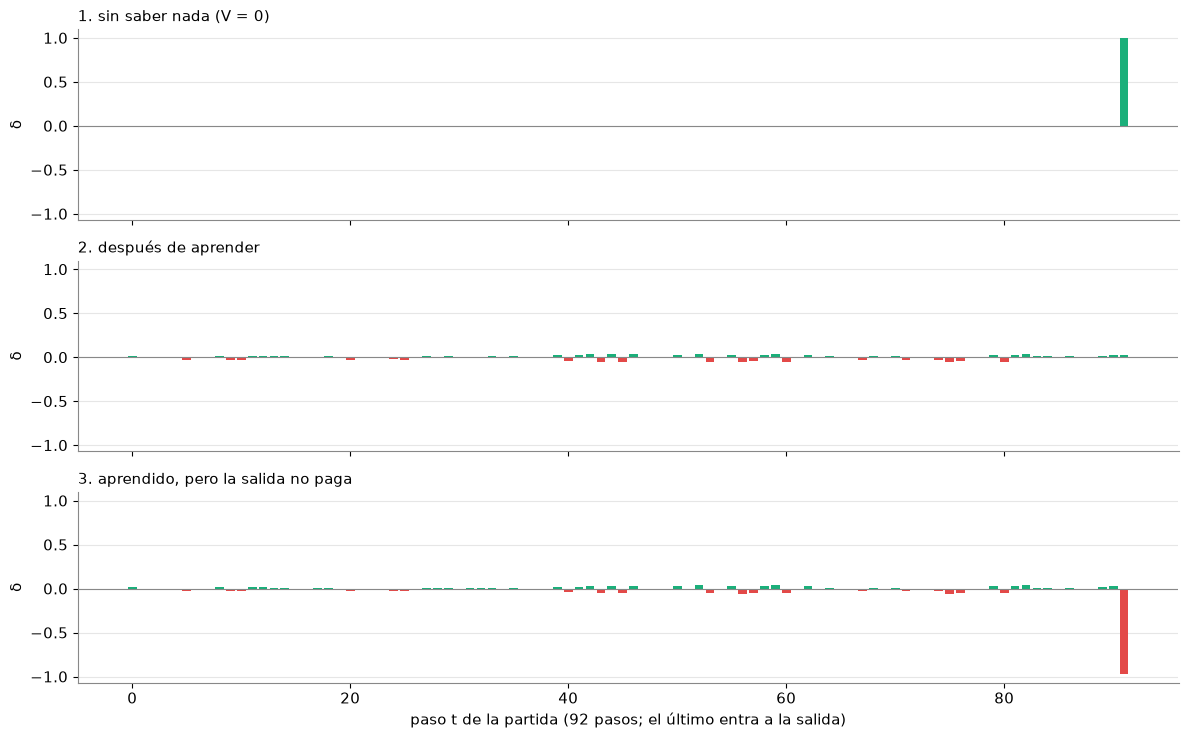

1. sin saber nada (V = 0)              δ del último paso = +1.000   |δ| más grande en los demás pasos = 0.000
2. después de aprender                 δ del último paso = +0.032   |δ| más grande en los demás pasos = 0.056
3. aprendido, pero la salida no paga   δ del último paso = -0.968   |δ| más grande en los demás pasos = 0.056

V aprendido de la última casilla (8, 11) = 0.968  (verdadero 0.969);  V aprendido de S = 0.506  (verdadero 0.500)
error RMS de TD después de 3000 partidas = 0.0099


In [14]:
rng = np.random.default_rng(30)
V_aprendido = np.zeros(env.nS)
for _ in range(3000):
    td0(V_aprendido, jugar(env, flechas, EPS, rng, inicio=inicio_al_azar(env, rng)), GAMMA, ALFA)

p5 = jugar(env, flechas, EPS, np.random.default_rng(31), inicio=env.start)
p5_sin_premio = [(s, a, 0.0, s2) for s, a, r, s2 in p5]

def deltas(V, partida):
    return np.array([r + GAMMA * V[s2] - V[s] for s, a, r, s2 in partida])

casos = [("1. sin saber nada (V = 0)", deltas(np.zeros(env.nS), p5)),
         ("2. después de aprender", deltas(V_aprendido, p5)),
         ("3. aprendido, pero la salida no paga", deltas(V_aprendido, p5_sin_premio))]
fig, axs = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, (nombre, d) in zip(axs, casos):
    ax.bar(np.arange(len(d)), d, color=np.where(d >= 0, COLORES[2], COLORES[7]), width=0.8)
    ax.axhline(0, color="#888888", lw=0.8)
    ax.set_title(nombre, loc="left", fontsize=11); ax.set_ylabel("δ"); ax.grid(axis="x", visible=False)
axs[-1].set_xlabel(f"paso t de la partida ({len(p5)} pasos; el último entra a la salida)")
plt.tight_layout(); plt.show()

for nombre, d in casos:
    print(f"{nombre:38s} δ del último paso = {d[-1]:+.3f}   |δ| más grande en los demás pasos = {np.abs(d[:-1]).max():.3f}")
s_ult = p5[-1][0]
print(f"\nV aprendido de la última casilla {env.free[s_ult]} = {V_aprendido[s_ult]:.3f}  (verdadero {V_true[s_ult]:.3f});  "
      f"V aprendido de S = {V_aprendido[env.start]:.3f}  (verdadero {V_true[env.start]:.3f})")
print(f"error RMS de TD después de 3000 partidas = {error_rms(V_aprendido, V_true, env):.4f}")

Las tres filas cuentan una historia:

1. **Sin saber nada**, toda la sorpresa está en el premio: $\delta = +1$ en el último paso y 0 en el resto.
2. **Después de aprender**, el premio sorprende mucho menos: el $\delta$ del último paso se achica a lo que todavía no estaba asegurado (desde la casilla de al lado, con tanto dado, entrar no era seguro). En el camino aparecen $\delta$ chicos de los dos signos: positivos cuando el dado acercó al agente a la salida, negativos cuando lo alejó.
3. **Si el premio esperado no llega**, la sorpresa es **negativa** justo en el momento en que tendría que haber llegado.

> **Recuadro: la dopamina como error de predicción.** En la clase 1 anunciamos esta conexión. Schultz, Dayan y Montague (1997) mostraron que ciertas neuronas de dopamina de monos se comportan como este $\delta$: antes del aprendizaje se activan cuando llega un jugo inesperado; cuando el mono aprende que una señal anuncia el jugo, se activan con la señal y ya no con el jugo; y si el jugo anunciado no llega, su actividad **cae por debajo de lo normal** en el momento en que tendría que haber llegado. Se parece a las filas 1 y 3 de la figura; la 2 muestra solo la mitad del traslado, porque en la cueva no hay una señal que anuncie el premio. **El límite:** es un modelo de una señal neuronal medida en experimentos de laboratorio, no una explicación de la conducta, del placer ni de la adicción. El cerebro no es una tabla de 60 casillas, y que una señal se parezca a $\delta$ no quiere decir que el cerebro haga TD(0).

## 6. Sesgo y varianza: Monte Carlo contra TD

Dos maneras de equivocarse al estimar un valor:

- **Sesgo** (*bias*): errar **para el mismo lado**, sistemáticamente. TD se apoya en sus propias estimaciones, que al principio valen 0: su objetivo $r + \gamma V(s')$ queda corto.
- **Varianza** (*variance*): **temblar** de partida en partida. Monte Carlo usa el retorno de la partida entera, que depende de todos los dados que se tiraron hasta el final; el objetivo de TD depende de un solo paso.

Como intuición (sin demostración): Monte Carlo no tiene sesgo pero varía más; TD tiene sesgo al principio y varía menos.

### Paso 1 — Error contra partidas, varios $\alpha$

Monte Carlo y TD ven **exactamente las mismas partidas** (cada una empieza en una casilla al azar). Comparamos Monte Carlo con $\alpha = 1/n$ (el promedio exacto), Monte Carlo con $\alpha$ fijo y TD con el mismo $\alpha$ fijo, para tres valores de $\alpha$, con 10 semillas y 3000 partidas. Medimos el **error RMS** contra el valor verdadero: la raíz del promedio de los errores al cuadrado en las 59 casillas. Tarda unos segundos.

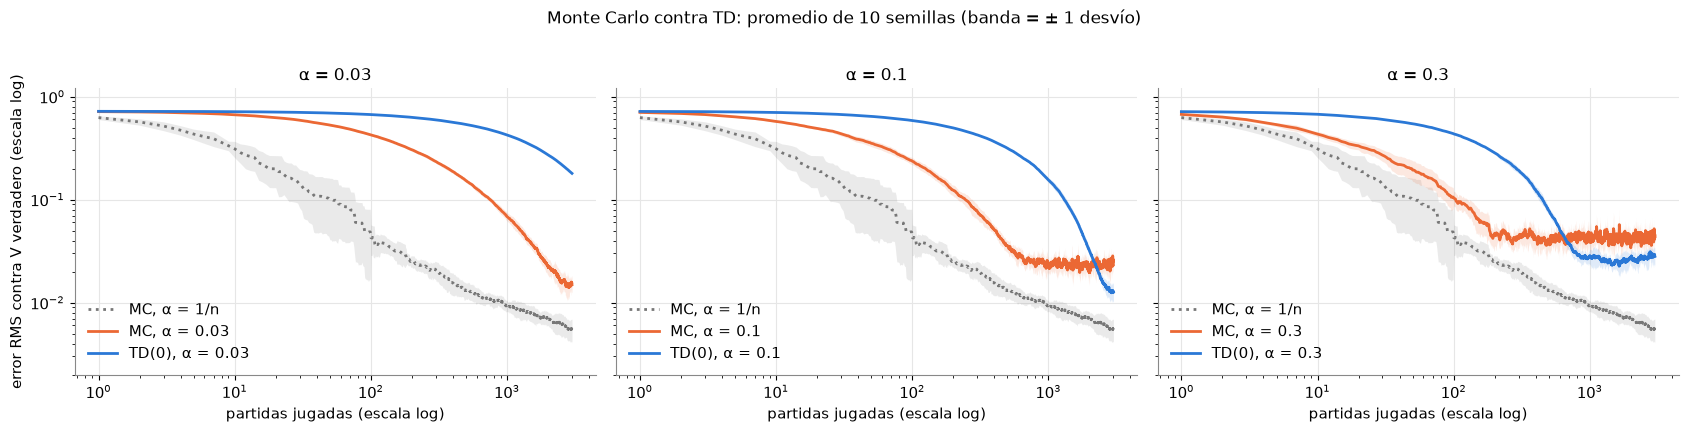

Error RMS promedio (10 semillas) después de N partidas:
método           N = 10     N = 30    N = 100    N = 300   N = 1000   N = 3000
MC 1/n           0.3111     0.1397     0.0428     0.0208     0.0093     0.0055
MC α=0.03        0.6666     0.5898     0.4261     0.2348     0.0684     0.0149
MC α=0.1         0.5738     0.4364     0.2361     0.0774     0.0241     0.0233
MC α=0.3         0.4328     0.2702     0.1033     0.0436     0.0447     0.0436
TD α=0.03        0.7139     0.7028     0.6693     0.5947     0.4237     0.1798
TD α=0.1         0.7016     0.6701     0.5860     0.4250     0.1544     0.0127
TD α=0.3         0.6736     0.6018     0.4349     0.1925     0.0285     0.0280

Piso de cada método: error RMS promedio en las partidas 2001–3000
   α = 0.03  MC = 0.0174   TD = 0.2225
   α = 0.1   MC = 0.0236   TD = 0.0182
   α = 0.3   MC = 0.0429   TD = 0.0274
   MC con α = 1/n = 0.0061


In [15]:
ALFAS = [0.03, 0.1, 0.3]
N_PARTIDAS = 3000
MARCAS = (10, 30, 100, 300, 1000, 3000)
res = comparar(env, flechas, EPS, V_true, GAMMA, ALFAS, N_PARTIDAS, semillas=range(10), marcas=MARCAS, casilla=cruce)
err = res["err"]
x = np.arange(1, N_PARTIDAS + 1)

fig, axs = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for ax, a in zip(axs, ALFAS):
    banda(ax, x, err["MC 1/n"], "#777777", "MC, α = 1/n", ls=":")
    banda(ax, x, err[f"MC α={a:g}"], COL_MC, f"MC, α = {a:g}")
    banda(ax, x, err[f"TD α={a:g}"], COL_TD, f"TD(0), α = {a:g}")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(2e-3, 1.2)
    ax.set_title(f"α = {a:g}"); ax.set_xlabel("partidas jugadas (escala log)")
    ax.legend(frameon=False, loc="lower left")
axs[0].set_ylabel("error RMS contra V verdadero (escala log)")
plt.suptitle("Monte Carlo contra TD: promedio de 10 semillas (banda = ± 1 desvío)", y=1.02)
plt.tight_layout(); plt.show()

print(f"Error RMS promedio (10 semillas) después de N partidas:")
print(f"{'método':12s}" + "".join(f"{'N = ' + str(m):>11s}" for m in MARCAS))
for nom in res["nombres"]:
    print(f"{nom:12s}" + "".join(f"{err[nom][:, m - 1].mean():>11.4f}" for m in MARCAS))
print(f"\nPiso de cada método: error RMS promedio en las partidas 2001–3000")
for a in ALFAS:
    print(f"   α = {a:<5g} MC = {err[f'MC α={a:g}'][:, 2000:].mean():.4f}   TD = {err[f'TD α={a:g}'][:, 2000:].mean():.4f}")
print(f"   MC con α = 1/n = {err['MC 1/n'][:, 2000:].mean():.4f}")

Lo que muestran las curvas:

- **Al principio, TD va atrás**: el +1 tiene que propagarse desde la salida hacia atrás, casilla por casilla, y mientras tanto todo lo que está lejos sigue cerca de 0. Ese es el sesgo de apoyarse en estimaciones que arrancaron mal. Cuanto más chico $\alpha$, más tarda.
- **Al final, con el mismo $\alpha$, TD queda más abajo** (cuando le alcanzan las partidas para llegar): las curvas dejan de bajar y se quedan temblando, y el piso de TD es más bajo que el de Monte Carlo. Con $\alpha$ fijo, lo que queda es varianza, y la de TD es menor.
- **Monte Carlo con $\alpha = 1/n$** no tiene sesgo y su $\alpha$ se achica solo, así que sigue bajando: en esta cueva chica, con partidas cortas que siempre terminan, es el que mejor anda. Un $\alpha$ fijo cambia rapidez por temblor.

### Paso 2 — Sesgo y temblor en una casilla

Para ver las dos cosas por separado, miramos el valor estimado del cruce, partida a partida, con $\alpha = 0{,}1$, en las 10 semillas.

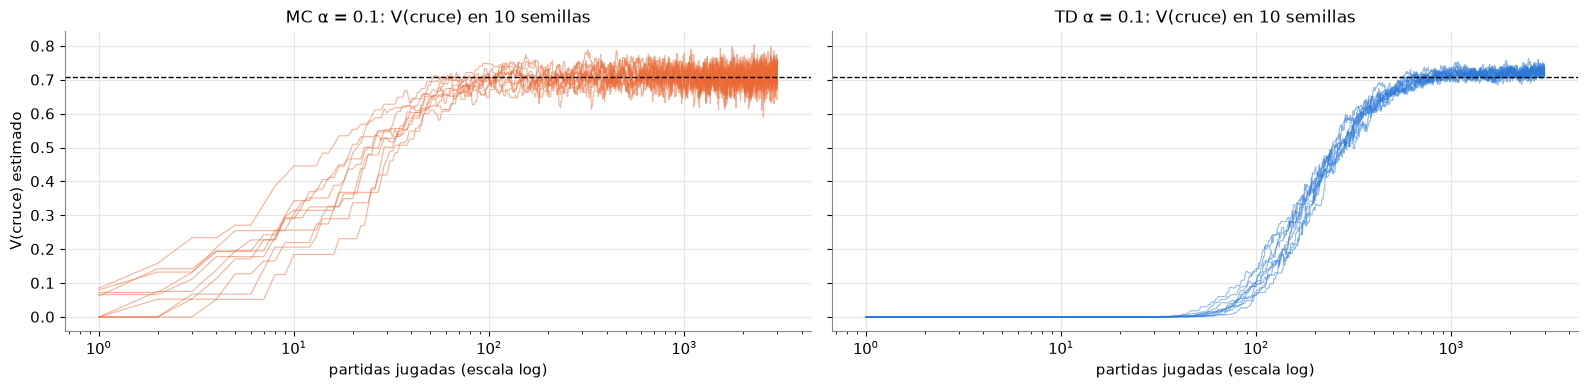

V verdadero del cruce = 0.7099
MC α=0.1  N =  100:  promedio de las 10 semillas − verdadero (sesgo) = -0.0060   semillas por debajo: 5 de 10
MC α=0.1  N =  300:  promedio de las 10 semillas − verdadero (sesgo) = +0.0006   semillas por debajo: 5 de 10
MC α=0.1  N = 3000:  promedio de las 10 semillas − verdadero (sesgo) = +0.0042   semillas por debajo: 6 de 10
TD α=0.1  N =  100:  promedio de las 10 semillas − verdadero (sesgo) = -0.6117   semillas por debajo: 10 de 10
TD α=0.1  N =  300:  promedio de las 10 semillas − verdadero (sesgo) = -0.1716   semillas por debajo: 10 de 10
TD α=0.1  N = 3000:  promedio de las 10 semillas − verdadero (sesgo) = +0.0127   semillas por debajo: 1 de 10
MC α=0.1  temblor de V(cruce) en las partidas 2001–3000 (desvío promedio por semilla) = 0.0272
TD α=0.1  temblor de V(cruce) en las partidas 2001–3000 (desvío promedio por semilla) = 0.0100


In [16]:
tr = res["traza"]
fig, axs = plt.subplots(1, 2, figsize=(16, 4), sharey=True)
for ax, nom, col in [(axs[0], "MC α=0.1", COL_MC), (axs[1], "TD α=0.1", COL_TD)]:
    for i in range(tr[nom].shape[0]):
        ax.plot(x, tr[nom][i], color=col, lw=0.8, alpha=0.5)
    ax.axhline(V_true[cruce], color="k", ls="--", lw=1)
    ax.set_xscale("log"); ax.set_xlabel("partidas jugadas (escala log)")
    ax.set_title(f"{nom.replace('α=', 'α = ')}: V(cruce) en 10 semillas")
axs[0].set_ylabel("V(cruce) estimado")
plt.tight_layout(); plt.show()

print(f"V verdadero del cruce = {V_true[cruce]:.4f}")
for nom in ["MC α=0.1", "TD α=0.1"]:
    for m in [100, 300, 3000]:
        v = tr[nom][:, m - 1]
        print(f"{nom:9s} N = {m:4d}:  promedio de las 10 semillas − verdadero (sesgo) = {v.mean() - V_true[cruce]:+.4f}   "
              f"semillas por debajo: {int(np.sum(v < V_true[cruce]))} de 10")
for nom in ["MC α=0.1", "TD α=0.1"]:
    v = tr[nom][:, 2000:]
    print(f"{nom:9s} temblor de V(cruce) en las partidas 2001–3000 (desvío promedio por semilla) = {v.std(axis=1).mean():.4f}")

Al principio, las semillas de TD están **todas por debajo** del verdadero: sesgo. Las de Monte Carlo llegan antes a rodear la línea punteada, pero cada una salta más de partida en partida: varianza. Al final las dos quedan centradas, y la de TD tiembla menos.

En esta cueva el retorno de una partida no varía tanto, así que Monte Carlo no sufre mucho por su varianza. En problemas con partidas largas y muy distintas (como el dado de la clase 3, o un tutor que acompaña a un alumno todo un año) la varianza de Monte Carlo pesa mucho más, y TD tiene otra ventaja: **no necesita que la partida termine** para aprender.

## 7. Armar el mapa con lo jugado: equivalencia de certeza

Una tercera idea: usar las partidas para **estimar el mapa** y después resolver Bellman como en las clases 3 y 4, como si el mapa estimado fuera el verdadero. Se llama **equivalencia de certeza** (*certainty equivalence*):

1. **Contar**: cuántas veces se pasó de $s$ a $s'$, y cuánto premio se cobró saliendo de $s$.
2. **Estimar**: $\hat P(s' \mid s) = \dfrac{\text{veces que fue de } s \text{ a } s'}{\text{veces que salió de } s}$ y $\hat R(s)$ = premio promedio al salir de $s$.
3. **Resolver**: $\hat V = (I - \gamma \hat P)^{-1} \hat R$.

Como evaluamos una política fija, alcanza con estimar la cadena $P^\pi$ de la clase 4 (una fila por casilla), sin separar por acción.

### Paso 1 — El mapa estimado con 300 partidas

Usamos las mismas 300 partidas de la sección 2 y comparamos dos filas de $\hat P$ con las verdaderas.

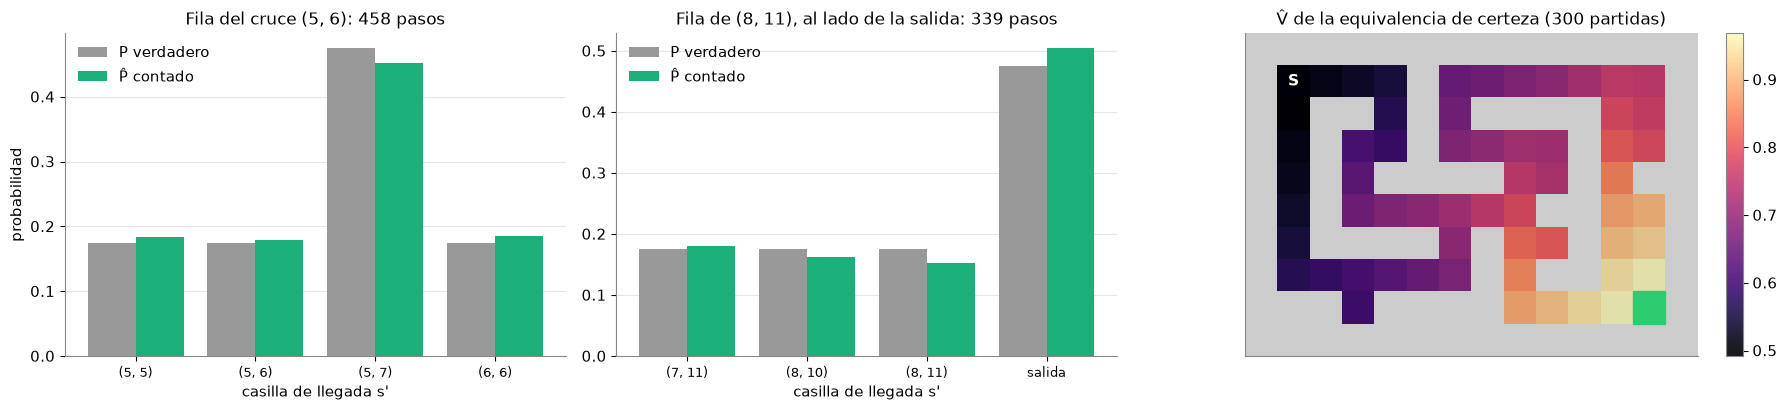

Fila del cruce: (5, 5): P̂ = 0.183 (P = 0.175),  (5, 6): P̂ = 0.179 (P = 0.175),  (5, 7): P̂ = 0.452 (P = 0.475),  (6, 6): P̂ = 0.186 (P = 0.175)
Fila de (8, 11): (7, 11): P̂ = 0.180 (P = 0.175),  (8, 10): P̂ = 0.162 (P = 0.175),  (8, 11): P̂ = 0.153 (P = 0.175),  salida: P̂ = 0.504 (P = 0.475)
R̂(8, 11) = 0.504   R verdadero = 0.475
error máximo de P̂ en toda la tabla = 0.165

V̂(S) = 0.5029   V̂(cruce) = 0.7219   (verdaderos: 0.5004 y 0.7099)
Con las mismas 300 partidas, error RMS:  equivalencia de certeza = 0.0101   Monte Carlo (α = 1/n) = 0.0169


In [17]:
cuentas, premios = np.zeros((env.nS, env.nS)), np.zeros(env.nS)
for p in partidas_mc:
    contar(cuentas, premios, p)
P_hat, R_hat, V_hat = certeza(cuentas, premios, GAMMA)

izq_salida = env.pos2s[(8, 11)]
nombre_casilla = lambda d: "salida" if d == env.goal else str(env.free[d])
fig, axs = plt.subplots(1, 3, figsize=(18, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.15]})
for ax, s, nombre in [(axs[0], cruce, "del cruce (5, 6)"), (axs[1], izq_salida, "de (8, 11), al lado de la salida")]:
    dest = np.flatnonzero((P_true[s] > 0) | (P_hat[s] > 0))
    xx = np.arange(len(dest))
    ax.bar(xx - 0.2, P_true[s, dest], width=0.4, color="#999999", label="P verdadero")
    ax.bar(xx + 0.2, P_hat[s, dest], width=0.4, color=COL_CE, label="P̂ contado")
    ax.set_xticks(xx); ax.set_xticklabels([nombre_casilla(d) for d in dest], fontsize=9)
    ax.set_title(f"Fila {nombre}: {int(cuentas[s].sum())} pasos"); ax.set_xlabel("casilla de llegada s'")
    ax.grid(axis="x", visible=False); ax.legend(frameon=False)
axs[0].set_ylabel("probabilidad")
plot_cave(env, values=V_hat, ax=axs[2], clim=CLIM, title="V̂ de la equivalencia de certeza (300 partidas)")
plt.tight_layout(); plt.show()

for s, nombre in [(cruce, "del cruce"), (izq_salida, "de (8, 11)")]:
    print(f"Fila {nombre}: " + ",  ".join(f"{nombre_casilla(d)}: P̂ = {P_hat[s, d]:.3f} (P = {P_true[s, d]:.3f})"
                                            for d in np.flatnonzero((P_true[s] > 0) | (P_hat[s] > 0))))
print(f"R̂(8, 11) = {R_hat[izq_salida]:.3f}   R verdadero = {R_true[izq_salida]:.3f}")
print(f"error máximo de P̂ en toda la tabla = {np.abs(P_hat - P_true)[ng].max():.3f}")
print(f"\nV̂(S) = {V_hat[env.start]:.4f}   V̂(cruce) = {V_hat[cruce]:.4f}   (verdaderos: {V_true[env.start]:.4f} y {V_true[cruce]:.4f})")
print(f"Con las mismas 300 partidas, error RMS:  equivalencia de certeza = {error_rms(V_hat, V_true, env):.4f}   "
      f"Monte Carlo (α = 1/n) = {error_rms(V_mc, V_true, env):.4f}")

Con 300 partidas, las filas de $\hat P$ ya se parecen a las verdaderas (con el ruido de contar), y el $\hat V$ que sale de resolver Bellman con ese mapa queda más cerca del verdadero que el promedio de Monte Carlo con las mismas partidas. ¿Por qué? Cada paso jugado informa sobre **una fila** de $\hat P$, y Bellman combina todas las filas: una casilla aprovecha también lo que se vio en sus vecinas.

### Paso 2 — Equivalencia de certeza contra Monte Carlo y TD

En la comparación de la sección 6 también contamos transiciones y resolvimos Bellman en algunas marcas (10, 30, 100, 300, 1000 y 3000 partidas). Las ponemos al lado de Monte Carlo y TD.

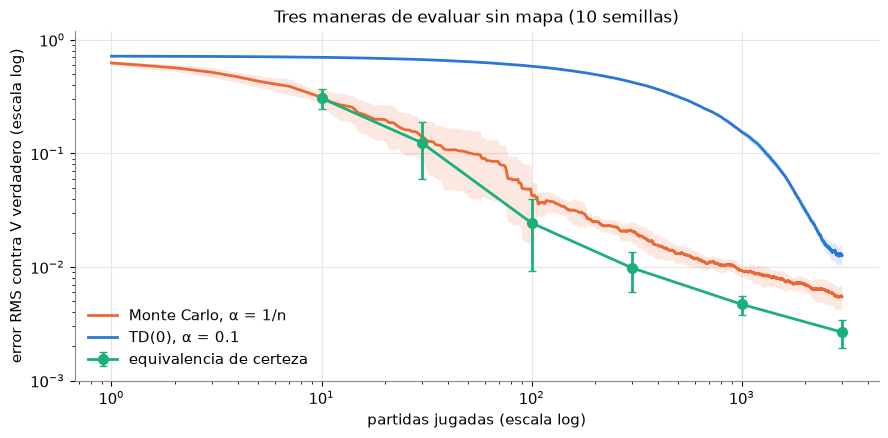

 N partidas   certeza    MC 1/n  TD α=0.1
         10    0.3061    0.3111    0.7016
         30    0.1242    0.1397    0.6701
        100    0.0244    0.0428    0.5860
        300    0.0098    0.0208    0.4250
       1000    0.0047    0.0093    0.1544
       3000    0.0027    0.0055    0.0127

Resolver Bellman con P̂ (60 casillas): 0.16 ms por vez.  Tamaño de P̂: 60 × 60 = 3600 números.


In [18]:
fig, ax = plt.subplots(figsize=(9, 4.5))
banda(ax, x, err["MC 1/n"], COL_MC, "Monte Carlo, α = 1/n")
banda(ax, x, err["TD α=0.1"], COL_TD, "TD(0), α = 0.1")
m_ce, sd_ce = res["err_ce"].mean(0), res["err_ce"].std(0)
ax.errorbar(MARCAS, m_ce, yerr=sd_ce, fmt="o-", color=COL_CE, ms=7, capsize=3, label="equivalencia de certeza")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-3, 1.2)
ax.set_xlabel("partidas jugadas (escala log)"); ax.set_ylabel("error RMS contra V verdadero (escala log)")
ax.set_title("Tres maneras de evaluar sin mapa (10 semillas)"); ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

print(f"{'N partidas':>11s} {'certeza':>9s} {'MC 1/n':>9s} {'TD α=0.1':>9s}")
for j, m in enumerate(MARCAS):
    print(f"{m:>11d} {m_ce[j]:>9.4f} {err['MC 1/n'][:, m - 1].mean():>9.4f} {err['TD α=0.1'][:, m - 1].mean():>9.4f}")

import time
t0 = time.perf_counter()
for _ in range(100):
    certeza(cuentas, premios, GAMMA)
dt = (time.perf_counter() - t0) / 100
print(f"\nResolver Bellman con P̂ (60 casillas): {1000 * dt:.2f} ms por vez.  Tamaño de P̂: {env.nS} × {env.nS} = {env.nS ** 2} números.")

La equivalencia de certeza es la que mejor usa los datos: con las mismas partidas, el error más bajo (con muy pocas partidas, empatada con Monte Carlo). El precio es otro: hay que **guardar una tabla $\hat P$** de casillas × casillas y **resolver un sistema** cada vez que se quiere el valor. En la cueva son 60 casillas y la cuenta tarda milisegundos; con millones de estados (una imagen, una conversación) la tabla no entra en memoria y el sistema no se puede resolver. Monte Carlo y TD, en cambio, solo guardan un número por casilla y hacen una cuenta chiquita por partida o por paso.

| método | cuándo actualiza | qué guarda | sesgo / varianza |
|---|---|---|---|
| Monte Carlo | al terminar la partida | un número por casilla | sin sesgo, más varianza |
| TD(0) | después de cada paso | un número por casilla | sesgo al principio, menos varianza |
| equivalencia de certeza | cuando se resuelve Bellman | la tabla $\hat P$ entera | usa todos los datos, cuesta resolver |

## ✍️ Ejercicio — Cambien $\alpha$ y la cantidad de partidas

Cambien `alfa_ej` y `partidas_ej` y ejecuten. La celda corre Monte Carlo ($\alpha = 1/n$ y $\alpha$ fijo) y TD(0) con 5 semillas y dibuja el error RMS.

Antes de ejecutar, **predigan**: con $\alpha = 0{,}5$, ¿quién baja más rápido al principio? ¿Quién queda más abajo al final? ¿Y con $\alpha = 0{,}01$ y solo 100 partidas?

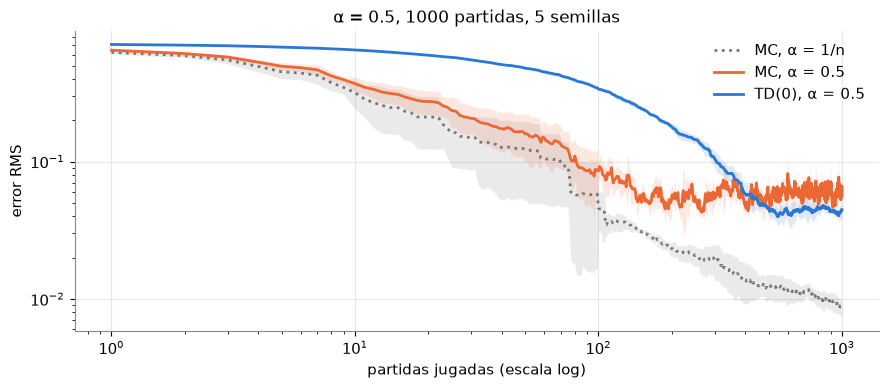

MC 1/n       error RMS final = 0.0086
MC α=0.5     error RMS final = 0.0655
TD α=0.5     error RMS final = 0.0446


In [19]:
alfa_ej = 0.5        # TODO: probá 0.01, 0.05, 0.5
partidas_ej = 1000   # TODO: probá 100, 3000

r_ej = comparar(env, flechas, EPS, V_true, GAMMA, [alfa_ej], partidas_ej, semillas=range(5))
xe = np.arange(1, partidas_ej + 1)
fig, ax = plt.subplots(figsize=(9, 4))
banda(ax, xe, r_ej["err"]["MC 1/n"], "#777777", "MC, α = 1/n", ls=":")
banda(ax, xe, r_ej["err"][f"MC α={alfa_ej:g}"], COL_MC, f"MC, α = {alfa_ej:g}")
banda(ax, xe, r_ej["err"][f"TD α={alfa_ej:g}"], COL_TD, f"TD(0), α = {alfa_ej:g}")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("partidas jugadas (escala log)")
ax.set_ylabel("error RMS"); ax.set_title(f"α = {alfa_ej}, {partidas_ej} partidas, 5 semillas"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
for nom in r_ej["nombres"]:
    print(f"{nom:12s} error RMS final = {r_ej['err'][nom][:, -1].mean():.4f}")

**Lo que encontramos** (¿quién baja antes? ¿quién queda más abajo? ¿cómo cambia con $\alpha$ y con la cantidad de partidas?):

-

## Preguntas para pensar

1. En la sección 4, TD en la primera partida solo corrigió la última casilla. ¿Cuántas partidas harían falta, como mínimo, para que le llegue algo de valor a una casilla a 20 pasos de la salida? ¿Y con Monte Carlo?
2. En la sección 5, el $\delta$ negativo apareció cuando el premio esperado no llegó. Piensen un ejemplo en el que «no pasó nada» se sintió como una mala noticia. ¿Qué expectativa había detrás?
3. Monte Carlo espera a ver cómo termina; TD corrige en cada paso con lo que esperaba del paso siguiente. Si quisieran evaluar a un tutor que acompaña a un alumno durante todo un año, ¿cuál usarían, y por qué?

## Próxima clase

Hoy evaluamos una política que nos dieron. ¿Cómo **elegir** mejores acciones sin mapa? En la clase 6, **controlar sin mapa**: SARSA y Q-learning usan este mismo $\delta$, pero sobre el valor de cada acción, $Q(s, a)$. Es el mismo paso que dimos en la clase 4, de evaluar una política a mejorarla con $Q$, ahora sin mapa.